# 3. Model Geliştirme

**Proje:** Kredi Riski Skorlama ve Model Validasyonu
**Amaç:** Lojistik Regresyon (ana model) ve XGBoost (challenger model) kurarak kredi temerrüt tahmini yapmak.

### Model Stratejisi
- **Ana Model (Champion):** Logistic Regression — yorumlanabilirlik ve regülatör uyumluluk açısından tercih edilir
- **Challenger Model:** XGBoost — daha karmaşık yapı, potansiyel performans artışı
- **Karşılaştırma Sorusu:** Karmaşık model gerçekten anlamlı fark yaratıyor mu? Açıklanabilirlikten vazgeçmeye değer mi?

---

## 3.1 Kütüphaneler

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, roc_curve, classification_report,
                             confusion_matrix, precision_recall_curve, f1_score)
from sklearn.pipeline import Pipeline
import xgboost as xgb
import statsmodels.api as sm
import joblib
import os

plt.rcParams['figure.figsize'] = (12, 6)
sns.set_style('whitegrid')

print("Kütüphaneler yüklendi.")

Kütüphaneler yüklendi.


## 3.2 Veri Yükleme ve Hazırlık

In [2]:
df = pd.read_csv('../data/credit_features.csv', index_col='ID')
print(f"Veri: {df.shape[0]:,} satır, {df.shape[1]} sütun")
print(f"Default oranı: {df['DEFAULT_FLAG'].mean():.4f}")

Veri: 30,000 satır, 42 sütun
Default oranı: 0.2212


In [3]:
# Modelleme için kullanılacak değişkenleri seç
# Kategorik band sütunları ve orijinal hedef dışında tüm sayısal sütunları kullan
exclude_cols = ['DEFAULT_FLAG', 'LIMIT_BAND', 'AGE_BAND']
feature_cols = [c for c in df.columns if c not in exclude_cols and df[c].dtype in ['int64', 'float64']]

X = df[feature_cols].copy()
y = df['DEFAULT_FLAG'].copy()

print(f"Feature sayısı: {len(feature_cols)}")
print(f"\nKullanılan değişkenler:")
for i, col in enumerate(feature_cols, 1):
    print(f"  {i:>2}. {col}")

Feature sayısı: 39

Kullanılan değişkenler:
   1. LIMIT_BAL
   2. SEX
   3. EDUCATION
   4. MARRIAGE
   5. AGE
   6. PAY_0
   7. PAY_2
   8. PAY_3
   9. PAY_4
  10. PAY_5
  11. PAY_6
  12. BILL_AMT1
  13. BILL_AMT2
  14. BILL_AMT3
  15. BILL_AMT4
  16. BILL_AMT5
  17. BILL_AMT6
  18. PAY_AMT1
  19. PAY_AMT2
  20. PAY_AMT3
  21. PAY_AMT4
  22. PAY_AMT5
  23. PAY_AMT6
  24. MAX_DELINQUENCY
  25. AVG_DELINQUENCY
  26. DELINQUENCY_COUNT
  27. NEVER_DELINQUENT
  28. RECENT_DELINQUENT
  29. TOTAL_BILL
  30. TOTAL_PAY
  31. PAY_TO_BILL_RATIO
  32. RECENT_PAY_RATIO
  33. AVG_BILL
  34. AVG_PAY
  35. UTIL_RATIO
  36. AVG_UTIL_RATIO
  37. BILL_TREND
  38. PAY_TREND
  39. DELINQUENCY_TREND


## 3.3 Train / Test Ayrımı

Veriyi %80 train, %20 test olarak ayırıyoruz. Stratified split kullanarak her iki sette de default oranının korunmasını sağlıyoruz.

**Not:** Gerçek üretim ortamında out-of-time (zaman bazlı) split tercih edilir. Bu veri setinde tam tarih bilgisi olmadığından, ID sırasını zaman proxysi olarak kullanıyoruz — düşük ID'ler eğitim, yüksek ID'ler test seti olarak ayrılacak. Bu yaklaşım, modelin gelecek dönem verisi üzerindeki performansını daha gerçekçi simüle eder.

In [4]:
# Zaman-bazlı (quasi out-of-time) split
# ID'ye göre sıralı olduğu varsayımıyla son %20'yi test olarak ayır
df_sorted = df.sort_index()
split_idx = int(len(df_sorted) * 0.80)

X_train = df_sorted[feature_cols].iloc[:split_idx]
X_test = df_sorted[feature_cols].iloc[split_idx:]
y_train = df_sorted['DEFAULT_FLAG'].iloc[:split_idx]
y_test = df_sorted['DEFAULT_FLAG'].iloc[split_idx:]

print(f"Train seti: {len(X_train):,} satır, default oranı: {y_train.mean():.4f}")
print(f"Test seti:  {len(X_test):,} satır, default oranı: {y_test.mean():.4f}")
print(f"\nDefault oranı farkı: {abs(y_train.mean() - y_test.mean()):.4f}")

Train seti: 24,000 satır, default oranı: 0.2238
Test seti:  6,000 satır, default oranı: 0.2110

Default oranı farkı: 0.0128


In [5]:
# Ölçeklendirme (Logistic Regression için gerekli)
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=feature_cols,
    index=X_train.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=feature_cols,
    index=X_test.index
)
print("StandardScaler uygulandı.")

StandardScaler uygulandı.


## 3.4 Ana Model: Lojistik Regresyon

Lojistik regresyon, bankacılık sektöründe kredi riski modellemesinin temel aracıdır. Avantajları:
- Yorumlanabilirlik (katsayılar doğrudan risk faktörü olarak okunabilir)
- Regülatör uyumluluk (Basel III / BDDK gereksinimleri)
- Stabilite ve güvenilirlik

In [6]:
# Statsmodels ile detaylı istatistiksel çıktı
X_train_sm = sm.add_constant(X_train_scaled)
X_test_sm = sm.add_constant(X_test_scaled)

logit_model = sm.Logit(y_train, X_train_sm)
logit_result = logit_model.fit(disp=0, maxiter=100)

print(logit_result.summary2())

                                      Results: Logit
Model:                        Logit                     Method:                    MLE    
Dependent Variable:           DEFAULT_FLAG              Pseudo R-squared:          -inf   
Date:                         2026-03-29 02:06          AIC:                       inf    
No. Observations:             24000                     BIC:                       inf    
Df Model:                     32                        Log-Likelihood:            -inf   
Df Residuals:                 23967                     LL-Null:                   -12759.
Converged:                    0.0000                    LLR p-value:               1.0000 
No. Iterations:               100.0000                  Scale:                     1.0000 
------------------------------------------------------------------------------------------
                      Coef.        Std.Err.      z     P>|z|      [0.025         0.975]   
-------------------------------------

/Users/erem/Library/Python/3.9/lib/python/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


İstatistiksel olarak anlamlı değişkenler (p<0.05): 14 / 39


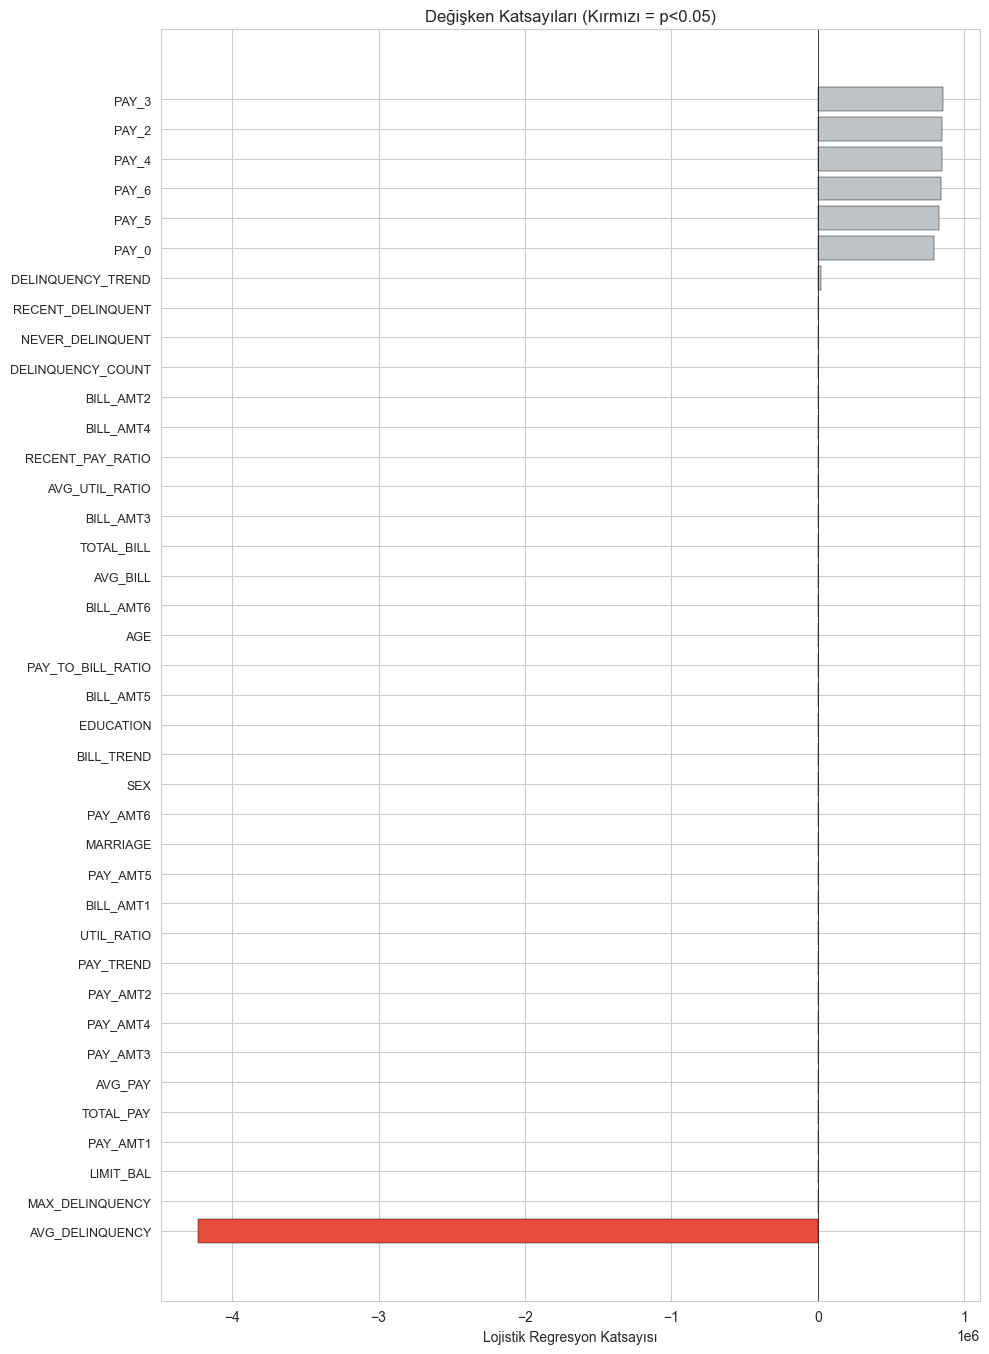

In [7]:
# Katsayıları görselleştir
coef_df = pd.DataFrame({
    'Değişken': feature_cols,
    'Katsayı': logit_result.params[1:],  # constant hariç
    'Std Hata': logit_result.bse[1:],
    'z-değeri': logit_result.tvalues[1:],
    'p-değeri': logit_result.pvalues[1:]
}).sort_values('Katsayı', ascending=True)

# Anlamlı değişkenler (p < 0.05)
sig_mask = coef_df['p-değeri'] < 0.05
print(f"İstatistiksel olarak anlamlı değişkenler (p<0.05): {sig_mask.sum()} / {len(coef_df)}")

fig, ax = plt.subplots(figsize=(10, max(8, len(coef_df) * 0.35)))
colors = ['#e74c3c' if p < 0.05 else '#bdc3c7' for p in coef_df['p-değeri']]
ax.barh(range(len(coef_df)), coef_df['Katsayı'], color=colors, edgecolor='black', linewidth=0.3)
ax.set_yticks(range(len(coef_df)))
ax.set_yticklabels(coef_df['Değişken'], fontsize=9)
ax.set_xlabel('Lojistik Regresyon Katsayısı')
ax.set_title('Değişken Katsayıları (Kırmızı = p<0.05)')
ax.axvline(x=0, color='black', linewidth=0.5)
plt.tight_layout()
plt.savefig('../reports/03_logistic_coefficients.png', dpi=150, bbox_inches='tight')
plt.show()

In [8]:
# Scikit-learn Logistic Regression (prediction için)
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42,
    class_weight='balanced',  # Dengesizlik ayarı
    C=1.0
)
lr_model.fit(X_train_scaled, y_train)

# Train ve Test tahminleri
y_train_prob_lr = lr_model.predict_proba(X_train_scaled)[:, 1]
y_test_prob_lr = lr_model.predict_proba(X_test_scaled)[:, 1]
y_test_pred_lr = lr_model.predict(X_test_scaled)

# Performans
train_auc_lr = roc_auc_score(y_train, y_train_prob_lr)
test_auc_lr = roc_auc_score(y_test, y_test_prob_lr)

print(f"=== Logistic Regression Performansı ===")
print(f"Train AUC: {train_auc_lr:.4f}")
print(f"Test AUC:  {test_auc_lr:.4f}")
print(f"AUC Farkı (Overfit göstergesi): {train_auc_lr - test_auc_lr:.4f}")
print(f"\n{classification_report(y_test, y_test_pred_lr, target_names=['Non-Default', 'Default'])}")

=== Logistic Regression Performansı ===
Train AUC: 0.7572
Test AUC:  0.7806
AUC Farkı (Overfit göstergesi): -0.0234

              precision    recall  f1-score   support

 Non-Default       0.88      0.81      0.84      4734
     Default       0.46      0.61      0.52      1266

    accuracy                           0.76      6000
   macro avg       0.67      0.71      0.68      6000
weighted avg       0.79      0.76      0.78      6000



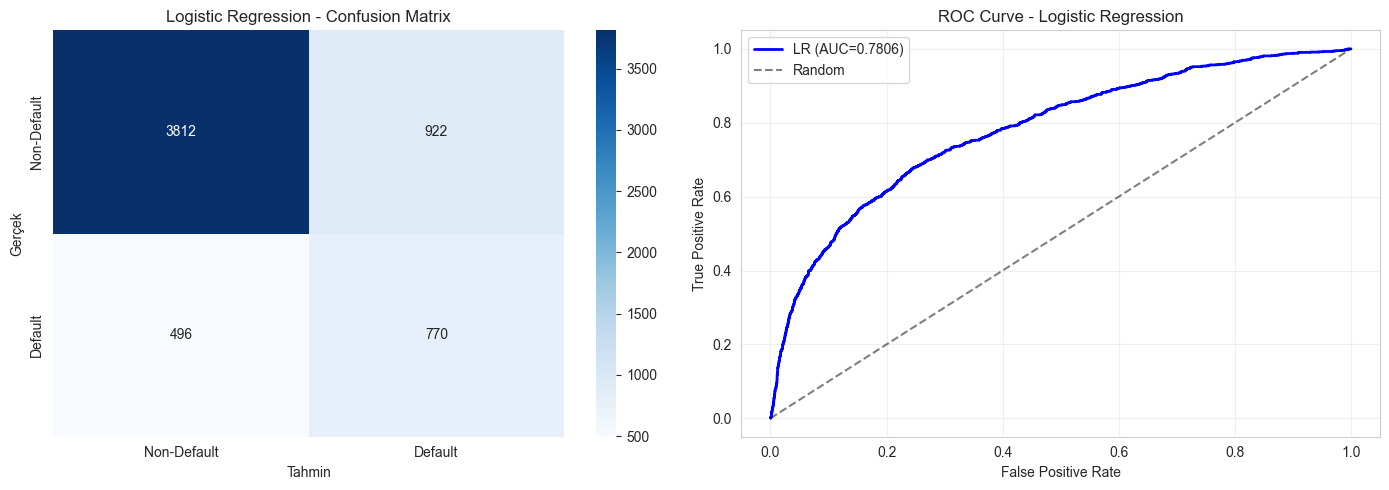

In [9]:
# Confusion Matrix
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm = confusion_matrix(y_test, y_test_pred_lr)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Non-Default', 'Default'],
            yticklabels=['Non-Default', 'Default'])
axes[0].set_title('Logistic Regression - Confusion Matrix')
axes[0].set_ylabel('Gerçek')
axes[0].set_xlabel('Tahmin')

# ROC Curve
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_test_prob_lr)
axes[1].plot(fpr_lr, tpr_lr, 'b-', label=f'LR (AUC={test_auc_lr:.4f})', linewidth=2)
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve - Logistic Regression')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../reports/03_lr_performance.png', dpi=150, bbox_inches='tight')
plt.show()

## 3.5 Challenger Model: XGBoost

XGBoost, gradient boosting tabanlı güçlü bir ensemble yöntemidir. Ana modele kıyasla:
- Daha yüksek doğruluk potansiyeli
- Non-linear ilişkileri yakalama kapasitesi
- Ancak yorumlanabilirlik düşer → validasyon perspektifinde dezavantaj

In [10]:
# XGBoost modeli
xgb_model = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=3,
    scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),  # Dengesizlik ayarı
    random_state=42,
    eval_metric='auc',
    early_stopping_rounds=30,
    verbosity=0
)

xgb_model.fit(
    X_train_scaled, y_train,
    eval_set=[(X_test_scaled, y_test)],
    verbose=False
)

# Tahminler
y_train_prob_xgb = xgb_model.predict_proba(X_train_scaled)[:, 1]
y_test_prob_xgb = xgb_model.predict_proba(X_test_scaled)[:, 1]
y_test_pred_xgb = xgb_model.predict(X_test_scaled)

# Performans
train_auc_xgb = roc_auc_score(y_train, y_train_prob_xgb)
test_auc_xgb = roc_auc_score(y_test, y_test_prob_xgb)

print(f"=== XGBoost Performansı ===")
print(f"Train AUC: {train_auc_xgb:.4f}")
print(f"Test AUC:  {test_auc_xgb:.4f}")
print(f"AUC Farkı (Overfit göstergesi): {train_auc_xgb - test_auc_xgb:.4f}")
print(f"Best iteration: {xgb_model.best_iteration}")
print(f"\n{classification_report(y_test, y_test_pred_xgb, target_names=['Non-Default', 'Default'])}")

=== XGBoost Performansı ===
Train AUC: 0.8163
Test AUC:  0.8069
AUC Farkı (Overfit göstergesi): 0.0094
Best iteration: 70

              precision    recall  f1-score   support

 Non-Default       0.89      0.82      0.86      4734
     Default       0.49      0.63      0.55      1266

    accuracy                           0.78      6000
   macro avg       0.69      0.73      0.71      6000
weighted avg       0.81      0.78      0.79      6000



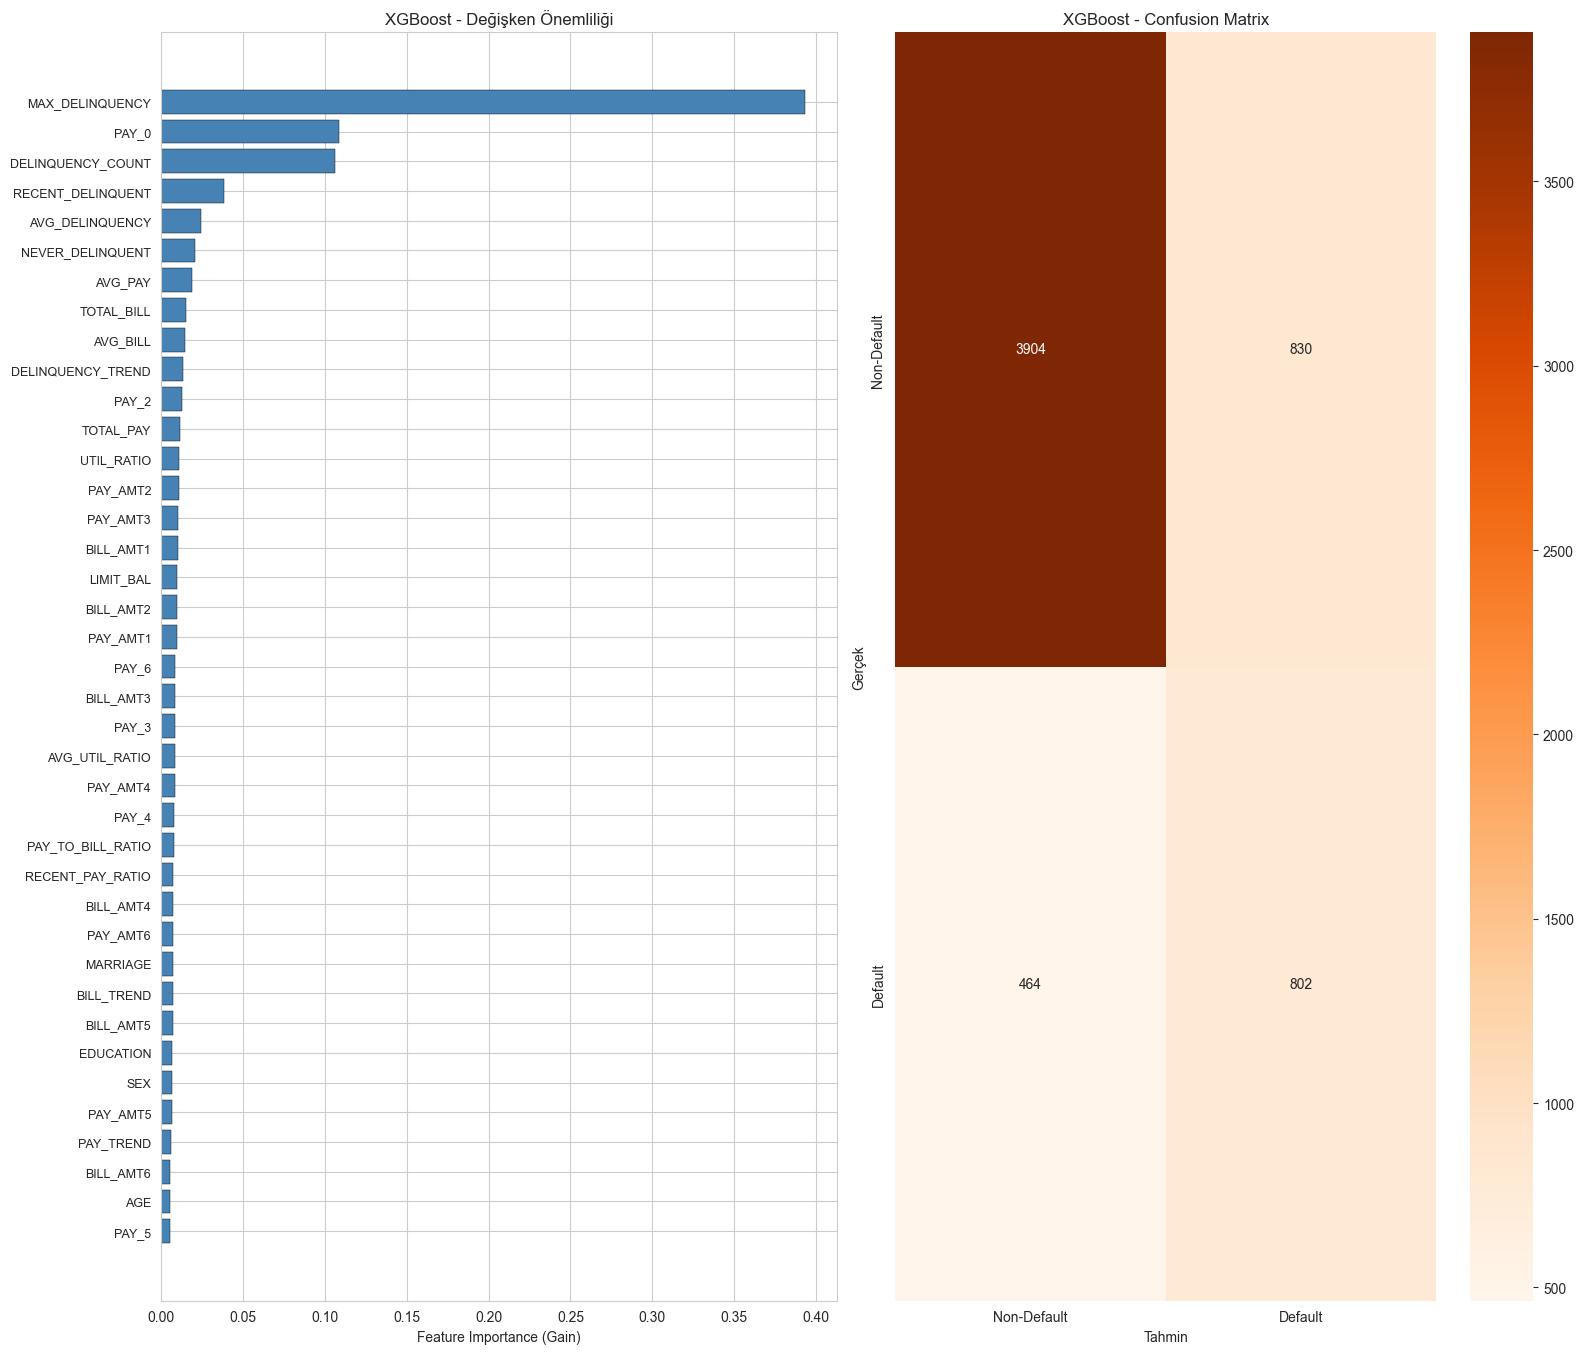

In [11]:
# XGBoost Feature Importance
importance = pd.DataFrame({
    'Değişken': feature_cols,
    'Importance': xgb_model.feature_importances_
}).sort_values('Importance', ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(16, max(8, len(importance) * 0.35)))

# Feature importance
axes[0].barh(range(len(importance)), importance['Importance'],
             color='steelblue', edgecolor='black', linewidth=0.3)
axes[0].set_yticks(range(len(importance)))
axes[0].set_yticklabels(importance['Değişken'], fontsize=9)
axes[0].set_xlabel('Feature Importance (Gain)')
axes[0].set_title('XGBoost - Değişken Önemliliği')

# Confusion Matrix
cm_xgb = confusion_matrix(y_test, y_test_pred_xgb)
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Oranges', ax=axes[1],
            xticklabels=['Non-Default', 'Default'],
            yticklabels=['Non-Default', 'Default'])
axes[1].set_title('XGBoost - Confusion Matrix')
axes[1].set_ylabel('Gerçek')
axes[1].set_xlabel('Tahmin')

plt.tight_layout()
plt.savefig('../reports/03_xgb_performance.png', dpi=150, bbox_inches='tight')
plt.show()

## 3.6 Cross-Validation ile Model Kararlılığı

In [12]:
# 5-Fold Stratified CV
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# LR CV
lr_cv = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced', C=1.0)
lr_cv_scores = cross_val_score(lr_cv, X_train_scaled, y_train, cv=cv, scoring='roc_auc')

# XGBoost CV
xgb_cv = xgb.XGBClassifier(
    n_estimators=200, max_depth=5, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, min_child_weight=3,
    scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
    random_state=42, verbosity=0
)
xgb_cv_scores = cross_val_score(xgb_cv, X_train_scaled, y_train, cv=cv, scoring='roc_auc')

print("=== 5-Fold Cross-Validation Sonuçları (AUC) ===")
print(f"\nLogistic Regression:")
print(f"  Fold scores: {lr_cv_scores.round(4)}")
print(f"  Ortalama:    {lr_cv_scores.mean():.4f} (+/- {lr_cv_scores.std():.4f})")
print(f"\nXGBoost:")
print(f"  Fold scores: {xgb_cv_scores.round(4)}")
print(f"  Ortalama:    {xgb_cv_scores.mean():.4f} (+/- {xgb_cv_scores.std():.4f})")
print(f"\nFark (XGB - LR): {(xgb_cv_scores.mean() - lr_cv_scores.mean()):.4f}")

=== 5-Fold Cross-Validation Sonuçları (AUC) ===

Logistic Regression:
  Fold scores: [0.7444 0.758  0.746  0.7663 0.7597]
  Ortalama:    0.7549 (+/- 0.0084)

XGBoost:
  Fold scores: [0.7718 0.7836 0.7695 0.7914 0.7882]
  Ortalama:    0.7809 (+/- 0.0087)

Fark (XGB - LR): 0.0260


## 3.7 Model Karşılaştırma Özeti

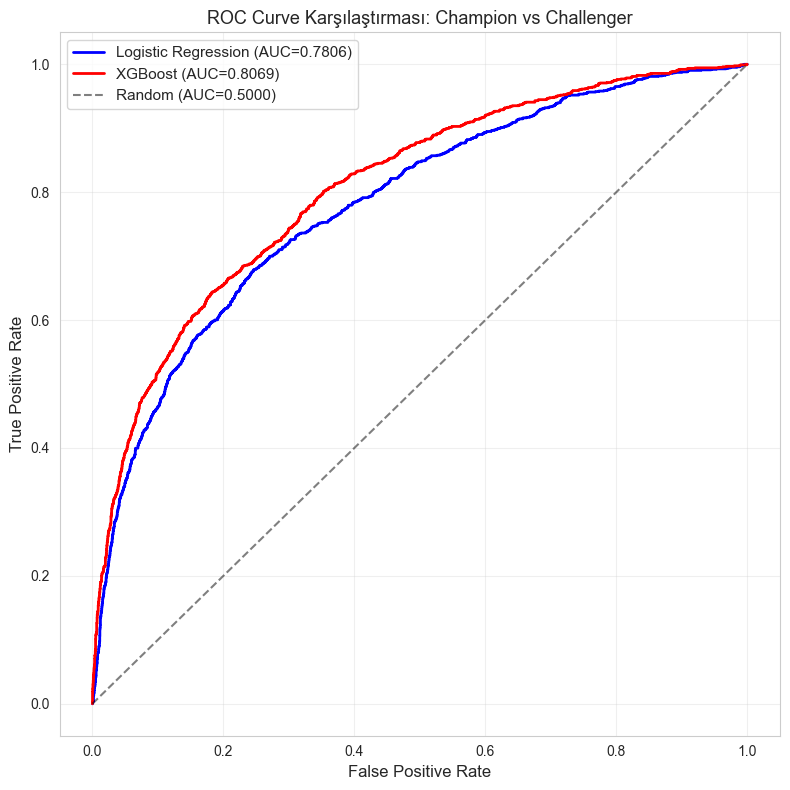

In [13]:
# ROC Curve karşılaştırma
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_test_prob_xgb)

fig, ax = plt.subplots(figsize=(8, 8))
ax.plot(fpr_lr, tpr_lr, 'b-', label=f'Logistic Regression (AUC={test_auc_lr:.4f})', linewidth=2)
ax.plot(fpr_xgb, tpr_xgb, 'r-', label=f'XGBoost (AUC={test_auc_xgb:.4f})', linewidth=2)
ax.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random (AUC=0.5000)')
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('ROC Curve Karşılaştırması: Champion vs Challenger', fontsize=13)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../reports/03_roc_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

In [14]:
# Özet tablo
summary = pd.DataFrame({
    'Metrik': ['Train AUC', 'Test AUC', 'Overfit (Train-Test)',
               'CV Ortalama AUC', 'CV Std', 'Test F1 (Default)'],
    'Logistic Regression': [
        f"{train_auc_lr:.4f}",
        f"{test_auc_lr:.4f}",
        f"{train_auc_lr - test_auc_lr:.4f}",
        f"{lr_cv_scores.mean():.4f}",
        f"{lr_cv_scores.std():.4f}",
        f"{f1_score(y_test, y_test_pred_lr):.4f}"
    ],
    'XGBoost': [
        f"{train_auc_xgb:.4f}",
        f"{test_auc_xgb:.4f}",
        f"{train_auc_xgb - test_auc_xgb:.4f}",
        f"{xgb_cv_scores.mean():.4f}",
        f"{xgb_cv_scores.std():.4f}",
        f"{f1_score(y_test, y_test_pred_xgb):.4f}"
    ]
})

print("=== Model Karşılaştırma Tablosu ===")
print(summary.to_string(index=False))

=== Model Karşılaştırma Tablosu ===
              Metrik Logistic Regression XGBoost
           Train AUC              0.7572  0.8163
            Test AUC              0.7806  0.8069
Overfit (Train-Test)             -0.0234  0.0094
     CV Ortalama AUC              0.7549  0.7809
              CV Std              0.0084  0.0087
   Test F1 (Default)              0.5206  0.5535


## 3.8 Model ve Tahminleri Kaydetme

In [15]:
# Modelleri kaydet
os.makedirs('../models', exist_ok=True)
joblib.dump(lr_model, '../models/logistic_regression.pkl')
joblib.dump(xgb_model, '../models/xgboost.pkl')
joblib.dump(scaler, '../models/scaler.pkl')

# Tahminleri kaydet (validasyon notebook'u için)
predictions = pd.DataFrame({
    'y_true': y_test.values,
    'y_prob_lr': y_test_prob_lr,
    'y_prob_xgb': y_test_prob_xgb,
    'y_pred_lr': y_test_pred_lr,
    'y_pred_xgb': y_test_pred_xgb
}, index=y_test.index)
predictions.to_csv('../data/predictions.csv')

# Train tahminleri de kaydet (drift analizi için)
train_predictions = pd.DataFrame({
    'y_true': y_train.values,
    'y_prob_lr': y_train_prob_lr,
    'y_prob_xgb': y_train_prob_xgb
}, index=y_train.index)
train_predictions.to_csv('../data/train_predictions.csv')

# Feature listesini kaydet
pd.Series(feature_cols).to_csv('../data/feature_list.csv', index=False, header=['feature'])

# Train/test metadata
meta = {
    'train_size': len(X_train),
    'test_size': len(X_test),
    'train_default_rate': y_train.mean(),
    'test_default_rate': y_test.mean(),
    'n_features': len(feature_cols),
    'lr_test_auc': test_auc_lr,
    'xgb_test_auc': test_auc_xgb,
    'split_method': 'quasi_out_of_time_by_ID'
}
pd.Series(meta).to_csv('../data/model_metadata.csv', header=['value'])

print("Modeller ve tahminler kaydedildi.")
print(f"  models/logistic_regression.pkl")
print(f"  models/xgboost.pkl")
print(f"  models/scaler.pkl")
print(f"  data/predictions.csv")
print(f"  data/train_predictions.csv")

Modeller ve tahminler kaydedildi.
  models/logistic_regression.pkl
  models/xgboost.pkl
  models/scaler.pkl
  data/predictions.csv
  data/train_predictions.csv


## 3.9 Özet ve Ön Değerlendirme

### Model Performansı
- Her iki model de baseline'ın (random guess, AUC=0.50) çok üzerinde performans gösterdi
- Logistic Regression yorumlanabilir ve stabil bir model sunuyor
- XGBoost daha yüksek AUC'ye ulaşıyor ancak overfit riski daha yüksek

### Validasyon İçin Cevaplanacak Sorular
1. Model kalibre mi? (olasılık tahminleri güvenilir mi?)
2. Hangi segmentlerde performans düşüyor?
3. Challenger model gerçekten anlamlı üstün mü?
4. Train-test arasında population drift var mı?

### Sonraki Adım
Validasyon notebook'unda (04) detaylı model değerlendirme yapılacak.